# SMILE-3 の検出器と座標系

チュートリアルを始める前に、SMILE-3 の検出器の構成と、**SMILE-2+ から変わったところ**、座標系をまとめます。
以降のノートブックのストリップの番号や座標は、すべてここで定義するものです。

## 1. ETCC(電子飛跡検出型コンプトンカメラ)

入射ガンマ線が TPC のガスの中でコンプトン散乱し、

- **反跳電子**の飛跡とエネルギー $K_e$ を **ガス TPC**(電子飛跡検出器。読み出しは μ-PIC)で、
- **散乱ガンマ線**の吸収位置とエネルギー $E_g$ を、TPC を囲む**シンチレータ(HA)**で

測ります。入射エネルギーは $E_0 = E_g + K_e$ です。

| 量 | 意味 |
|---|---|
| 散乱角 $\phi$ | 入射ガンマ線と散乱ガンマ線のなす角。$\cos\phi = 1 - m_ec^2\left(\frac{1}{E_g} - \frac{1}{E_g + K_e}\right)$ |
| $\alpha$ | 散乱ガンマ線と反跳電子のなす角。エネルギーから求めた値と飛跡から求めた値を比べると、イベントの選択に使える |
| event circle | 散乱ガンマ線の向きと $\phi$ だけからは、到来方向は円錐(天球上の円)までしか決まらない |
| ARM | 円の半径方向の分解能(Angular Resolution Measure)。主にエネルギー分解能で決まる |
| SPD | 円の周方向の分解能(Scatter Plane Deviation)。**電子の向きを測るので円の上の 1 点に絞れる**。電子飛跡を測る ETCC の特徴 |

TPC の中では、ガンマ線が当たって出た電子がガスを電離しながら走り、電離した電子が電場で μ-PIC までドリフトします。
μ-PIC は直交する 2 方向のストリップ(アノードとカソード)で、ヒットしたストリップの番号から平面の位置を、
到着時刻(クロック)から深さを求めて、電子の飛跡を 3 次元で測ります。各ボードの FADC では、ストリップをまとめた信号の波形を記録し、
その積分から電子のエネルギーを求めます。

## 2. SMILE-2+ からの変更点

| | SMILE-2+ | SMILE-3 |
|---|---|---|
| ① μ-PIC | 1 枚(30 cm 角)。アノード 3 ボード × 128 本、カソード 3 ボード × 128 本 | **4 分割**(パネル 0〜3)。パネルごとにアノード 3 ボード・カソード 3 ボード、全部でアノード 12 ボード(A0〜A11)、カソード 12 ボード(C0〜C11) |
| ② ストリップの間隔 | 0.8 mm(384 本 × 0.8 mm = 307.2 mm) | **0.4 mm**(1 パネル 384 本 × 0.4 mm = 153.6 mm、2 × 2 枚で 307.2 mm) |
| ③ シンチの読み出し(PSA) | PMT。ADC の値(波高)だけを記録 | **MPPC**。**波形**(50 サンプル)を記録する |

パネルとボードの組み合わせ:

| パネル | アノード | カソード |
|---|---|---|
| 0 | A0, A1, A2 | C0, C1, C2 |
| 1 | A3, A4, A5 | C3, C4, C5 |
| 2 | A6, A7, A8 | C6, C7, C8 |
| 3 | A9, A10, A11 | C9, C10, C11 |

アノードとカソードの組み(同時に鳴ったヒット)は、**同じパネルの中だけ**で作ります(`CalcFADC`、`TPC_Calibration` もそうしている)。
テストデータでは、つないでいないボードがあることがあります(下の 4 節で、ランごとに確かめる)。

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# リポジトリの場所と、設定ファイル(config/*.json)の読み込み
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "run_script" / "run_chain.py").exists())
sys.path.insert(0, str(REPO / "config"))
import ericanext_config as ec

PITCH = 0.4          # ストリップの間隔 [mm]
N_STRIP = 384        # 1 パネルのストリップの数(3 ボード × 128 本)
HALF = PITCH * N_STRIP   # 1 パネルの幅 153.6 mm

## 3. 検出器の配置(上から見た図)

上から見た図です(下の 5 節の座標系で、$X$ は右、$Y$ は下(S の方)、$Z$ は紙面の奥(下向き))。

- 中央の 4 枚が μ-PIC のパネル 0〜3。各パネルの 2 辺にアノード・カソードのボードが付きます。
- 底面のシンチ HA0〜HA5 は μ-PIC の下、側面のシンチは 4 面に 3 台ずつ(N: HA6〜8、W: HA9〜11、S: HA12〜14、E: HA15〜17)。

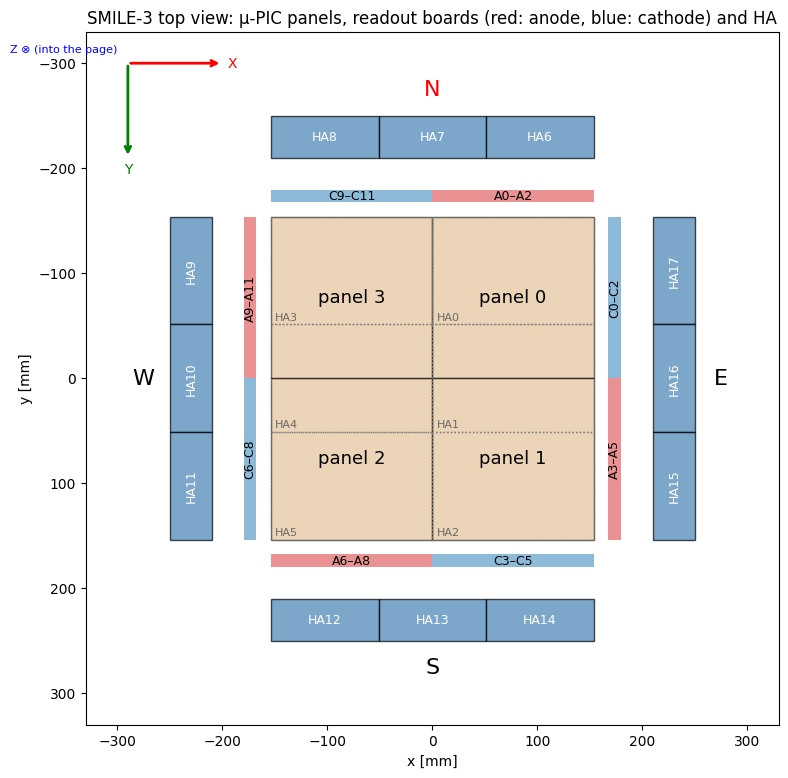

In [2]:
# パネルの範囲 (x0, x1, y0, y1) [mm](Y は下向き)と、ボードが付く辺
PANELS = {0: (0, HALF, -HALF, 0), 1: (0, HALF, 0, HALF), 2: (-HALF, 0, 0, HALF), 3: (-HALF, 0, -HALF, 0)}
EDGES = {   # (パネル, 辺, ラベル)
    "A": [(0, "N", "A0–A2"), (1, "E", "A3–A5"), (2, "S", "A6–A8"), (3, "W", "A9–A11")],
    "C": [(0, "E", "C0–C2"), (1, "S", "C3–C5"), (2, "W", "C6–C8"), (3, "N", "C9–C11")],
}
COL = {"A": "tab:red", "C": "tab:blue"}

def edge_box(panel, side, d=14, w=12):
    x0, x1, y0, y1 = PANELS[panel]
    return {"N": (x0, y0 - d - w, x1 - x0, w), "S": (x0, y1 + d, x1 - x0, w),
            "W": (x0 - d - w, y0, w, y1 - y0), "E": (x1 + d, y0, w, y1 - y0)}[side]

fig, ax = plt.subplots(figsize=(9, 9))
for p, (x0, x1, y0, y1) in PANELS.items():
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="burlywood", ec="k", alpha=0.6))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"panel {p}", ha="center", va="center", fontsize=13)
for kind, edges in EDGES.items():
    for p, side, label in edges:
        x, y, w, h = edge_box(p, side)
        ax.add_patch(Rectangle((x, y), w, h, fc=COL[kind], alpha=0.5))
        ax.text(x + w / 2, y + h / 2, label, ha="center", va="center", fontsize=9,
                rotation=90 if side in "EW" else 0)
# 底面のシンチ(2 列 × 3 行、点線)
for ha, (cx, cy) in {0: (1, -1), 1: (1, 0), 2: (1, 1), 3: (-1, -1), 4: (-1, 0), 5: (-1, 1)}.items():
    x, y = cx * HALF / 2, cy * 2 * HALF / 3
    ax.add_patch(Rectangle((x - HALF / 2, y - HALF / 3), HALF, 2 * HALF / 3, fill=False, ec="gray", ls=":"))
    ax.text(x - HALF / 2 + 4, y + HALF / 3 - 4, f"HA{ha}", color="dimgray", fontsize=8)   # 左下の角
# 側面のシンチ
R, W = 230, 40
side_ha = {"N": [8, 7, 6], "S": [12, 13, 14], "W": [9, 10, 11], "E": [17, 16, 15]}
for side, has in side_ha.items():
    for k, ha in enumerate(has):
        c = (k - 1) * 2 * HALF / 3
        x, y = {"N": (c, -R), "S": (c, R), "W": (-R, c), "E": (R, c)}[side]
        w, h = (2 * HALF / 3, W) if side in "NS" else (W, 2 * HALF / 3)
        ax.add_patch(Rectangle((x - w / 2, y - h / 2), w, h, fc="steelblue", ec="k", alpha=0.7))
        ax.text(x, y, f"HA{ha}", ha="center", va="center", color="w", fontsize=9,
                rotation=90 if side in "EW" else 0)
    tx, ty = {"N": (0, -R - 45), "S": (0, R + 45), "W": (-R - 45, 0), "E": (R + 45, 0)}[side]
    ax.text(tx, ty, side, ha="center", va="center", fontsize=16, color="red" if side == "N" else "k")
# 軸
ax.annotate("", xy=(-200, -300), xytext=(-290, -300), arrowprops=dict(arrowstyle="->", color="r", lw=2))
ax.annotate("", xy=(-290, -210), xytext=(-290, -300), arrowprops=dict(arrowstyle="->", color="g", lw=2))
ax.text(-195, -300, "X", color="r", va="center"); ax.text(-290, -195, "Y", color="g", ha="center")
ax.text(-300, -310, "Z ⊗ (into the page)", color="b", ha="right", fontsize=8)
ax.set_xlim(-330, 330); ax.set_ylim(330, -330)   # Y は下向き
ax.set_aspect("equal"); ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm]")
ax.set_title("SMILE-3 top view: μ-PIC panels, readout boards (red: anode, blue: cathode) and HA")
plt.show()

## 4. ストリップの番号とボード

`ReadData` は、生データのファイル名のボード番号(`tpc_enc_a<ボード>_*.raw`、`tpc_enc_c<ボード>_*.raw`)から、
ストリップに全体の通し番号を付けます。

$$\mathrm{strip} = 128 \times \mathrm{board} + 32 \times \mathrm{ch} + \mathrm{bit}\qquad(0 \sim 1535)$$

| | 式 |
|---|---|
| ボード | `strip // 128`(アノードなら A0〜A11、カソードなら C0〜C11) |
| パネル | `strip // 384`(= ボード // 3) |
| パネルの中の番号 | `strip % 384`(0〜383) |

FADC はボードごとに 4 ch(1 ch が 32 本のストリップの和)で、全部でアノード 48 ch、カソード 48 ch です。

下のセルで、設定ファイルのラン(`config/smile3_tpc_only.json` の `ReadData.data_dir`)にどのボードがあるかを確かめます。
ほかのランを見るときは `RUN_DIR` を書き換えてください。

In [3]:
cfg = ec.load("smile3_tpc_only")
RUN_DIR = Path(cfg["parameters"]["ReadData"]["data_dir"])
# 設定ファイルのランが無ければ、リポジトリの test.data/ のランを使う
if not RUN_DIR.is_dir():
    runs = sorted((REPO / "test.data").glob("run_*"))
    RUN_DIR = runs[0] if runs else RUN_DIR
print("run:", RUN_DIR)

def boards(kind):
    # ReadData と同じく、<種類><ボード>_00000.raw があるボード
    return [b for b in range(12) if (RUN_DIR / f"tpc_enc_{kind}{b:02d}_00000.raw").exists()]

if RUN_DIR.is_dir():
    have = {"a": boards("a"), "c": boards("c")}
    print(f"{'panel':>5}  {'anode':<16}{'cathode':<16}")
    for p in range(4):
        cols = []
        for k, name in (("a", "A"), ("c", "C")):
            cols.append(" ".join(f"{name}{b}" if b in have[k] else f"({name}{b})" for b in range(3 * p, 3 * p + 3)))
        print(f"{p:>5}  {cols[0]:<16}{cols[1]:<16}")
    print("( ) = このランには無いボード")
    meta = RUN_DIR / "run_meta.json"
    if meta.exists():
        m = json.loads(meta.read_text())
        print("run_meta.json: mode =", m.get("mode"), " active_detectors:", len(m.get("active_detectors", [])))
else:
    print("ランのディレクトリがありません。RUN_DIR を書き換えてください。")

run: /home/onoda/ANLNext/Erica_git_dev/EricaNext/test.data/run_20260623T072649Z
panel  anode           cathode         
    0  A0 A1 A2        C0 (C1) C2      
    1  A3 A4 A5        C3 C4 C5        
    2  A6 A7 A8        C6 C7 C8        
    3  A9 A10 A11      C9 C10 C11      
( ) = このランには無いボード
run_meta.json: mode = TPC_cal  active_detectors: 23


ericanext_config: WARNING: no storage_g*/ in /home/onoda/ANLNext/Erica_git_dev/EricaNext/mount_data (from DATA_DIR (mount_data/)). SMILE3_DATA must be the directory that holds storage_g0/ etc.


## 5. 座標系

| | 定義 |
|---|---|
| 原点 | μ-PIC の中央(4 枚のパネルの角が集まる所) |
| X 軸 | 上から見て右(W → E) |
| Y 軸 | 上から見て下(N → S) |
| Z 軸 | **下向き**(μ-PIC からドリフト領域・底面のシンチの方へ。上の図の ⊗) |

パネルの中の番号(アノード $a$、カソード $c$、どちらも 0〜383)から全体の位置への変換は、パネルごとに 90° ずつ回ります。
次の変換が `TPC_Calibration` にコメントで残っています(上の図のボードの付き方と合う。**まだチェーンでは使っていないので、データで確かめる必要があります**)。

| パネル | $t_x$ | $t_y$ |
|---|---|---|
| 0 | $384 + a$ | $c$ |
| 1 | $767 - c$ | $384 + a$ |
| 2 | $383 - a$ | $767 - c$ |
| 3 | $c$ | $383 - a$ |

$$x = 0.4\,(t_x - 383.5)\ \mathrm{mm},\qquad y = 0.4\,(t_y - 383.5)\ \mathrm{mm}$$

Z はドリフト時間(クロック)から求めます(`TOT_Skewness`: $z = \mathrm{pitch_z}\,(\mathrm{clock} - \mathrm{clock\_offset}) + z_\mathrm{GEM}$、GEM 面は μ-PIC から $z_\mathrm{GEM}$ = 10 mm、ドリフト長(μ-PIC から天板まで)は 317 mm。`clock_offset` とドリフト速度 $\mathrm{pitch_z}$ は SMILE-3 ではまだ測っておらず、SMILE-2+ の典型値を使っている)。

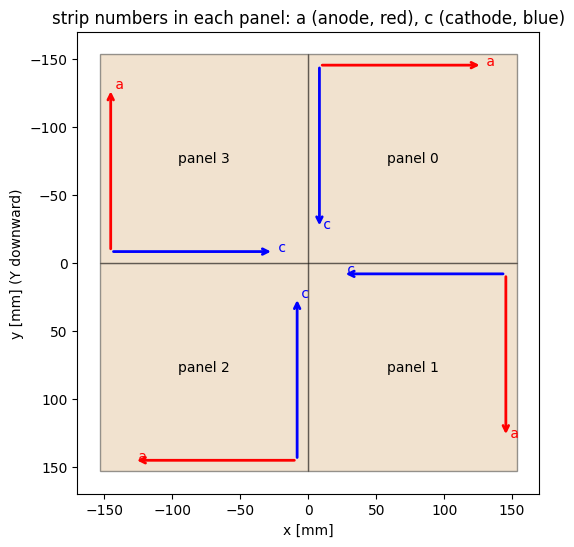

In [4]:
def to_xy(panel, a, c):
    # パネルの中の番号 (a, c) -> (x, y) [mm]。TPC_Calibration のコメントの変換
    a, c = np.asarray(a), np.asarray(c)
    tx, ty = {0: (384 + a, c), 1: (767 - c, 384 + a), 2: (383 - a, 767 - c), 3: (c, 383 - a)}[panel]
    return PITCH * (tx - 383.5), PITCH * (ty - 383.5)

# 各パネルで、アノード番号 a が増える向き(赤)とカソード番号 c が増える向き(青)
fig, ax = plt.subplots(figsize=(6, 6))
for p, (x0, x1, y0, y1) in PANELS.items():
    ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fc="burlywood", ec="k", alpha=0.4))
    o = np.array(to_xy(p, 20, 20))
    for (da, dc), col, lab in (((300, 0), "r", "a"), ((0, 300), "b", "c")):
        e = np.array(to_xy(p, 20 + da, 20 + dc))
        ax.annotate("", xy=e, xytext=o, arrowprops=dict(arrowstyle="->", color=col, lw=2))
        ax.text(*e, f" {lab}", color=col)
    ax.text((x0 + x1) / 2, (y0 + y1) / 2, f"panel {p}", ha="center", va="center")
ax.set_xlim(-170, 170); ax.set_ylim(170, -170); ax.set_aspect("equal")
ax.set_xlabel("x [mm]"); ax.set_ylabel("y [mm] (Y downward)")
ax.set_title("strip numbers in each panel: a (anode, red), c (cathode, blue)")
plt.show()

## 6. シンチの読み出し(PSA):MPPC と波形

SMILE-3 では、シンチ(HA)の読み出しが PMT から **MPPC** に変わり、**波形**を記録するようになりました。
解析のスクリプトは今のところ EricaNext の外(`~/PSA_analysis`)にあります。

| 項目 | 中身 |
|---|---|
| ボード | HA モジュールごとに PSA ボード 1 枚。ファイル名に FPGA の SN が入る(`<日付>_<時刻>_<FPGA_SN>_<番号>.dat`) |
| ch | 1 ボード 6 ch(MPPC 6 個。温度センサーも 6 個: TL, TR, ML, MR, BL, BR) |
| 1 ch の信号 | 抵抗分割で 4 隅の信号に分け、それぞれ **High Gain(HG)と Low Gain(LG)** で読む → 8 本 |
| 波形 | 1 イベント・1 ch あたり **50 サンプル**、ADC は 14 bit(16383 で飽和) |
| ペデスタル | 波形の最初の 23 サンプルの平均 |
| 積分 | ペデスタルを引いて、ピーク(LG の 4 本の和が最大のサンプル)の前 4 〜後 9 サンプルを台形積分(固定の窓 25〜41 も選べる) |
| エネルギー | HG の 4 本の積分の和 $S_H = I_0 + I_1 + I_2 + I_3$(LG も同じく $S_L$) |
| 位置 | $x = (I_0 - I_1 - I_2 + I_3)/S_H$、$y = (-I_0 - I_1 + I_2 + I_3)/S_H$(重心)。ここから 8 × 8 のピクセルを決める |

`~/PSA_analysis/src_onoda` の処理の流れ:

| スクリプト | すること |
|---|---|
| `psa_decode.py` | `.dat` → `.h5`(ヒットごとの `hg`, `lg`, `x_hg`, `y_hg`, 温度など。`--adc` で波形も `_adc.h5` に) |
| `peak_search.py` | 位置の 2 次元分布(バタフライマップ)から 64 個のピクセルのピークを探す |
| `grid_spect.py` | ピークの位置から、歪んだ格子を 8 × 8 のまっすぐな格子に直す補正(`grid_correction.npz`)を作る |
| `pixel_id.py` | その補正を新しいデータに当てて、ヒットごとのピクセル `(pix_n, pix_m)` を決める |

下のセルは、`.dat` から最初のイベントの波形を読んで描きます(`psa_decode.py` と同じ読み方)。
データの場所は `PSA_DATA`(環境変数 `SMILE3_PSA_DATA`、無ければ `~/analysis_sm3_FM/PSA_analysis/data/cal_psa/run_yamagata`)です。

20261012_180708_0247B655C19D_0.dat : 200 events read


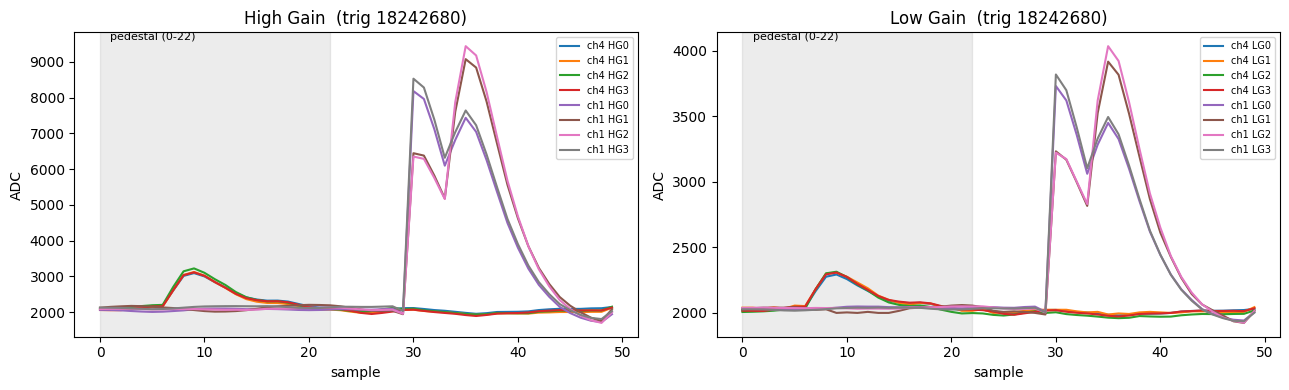

In [5]:
PSA_DATA = Path(os.environ.get("SMILE3_PSA_DATA", Path.home() / "analysis_sm3_FM" / "PSA_analysis" / "data" / "cal_psa" / "run_yamagata"))
HEADER, FOOTER = bytes([0xEB, 0x90, 0x19, 0x64]), b"uPIC"   # イベントの始まりと終わり
ADC_CH = {1: 0, 2: 1, 4: 2, 8: 3, 16: 4, 32: 5}               # ブロックの ch のビット -> ch 番号

def read_psa_events(path, n_events=200):
    # .dat の先頭から n_events 個のイベントを読み、[(trig, {ch: 波形 (50 サンプル × 8 本: HG0-3, LG0-3)})] を返す
    buf = path.read_bytes()[: 4 * 1024 * 1024]
    events, i = [], buf.find(HEADER)
    while i >= 0 and len(events) < n_events:
        j = buf.find(FOOTER, i + 4)
        if j < 0:
            break
        ev = np.frombuffer(buf[i:j + 4], np.uint8)
        trig = int.from_bytes(ev[4:8].tobytes(), "big")
        blocks = ev[0x24:len(ev) - 4]
        blocks = blocks[: len(blocks) // 16 * 16].reshape(-1, 4, 4).astype(np.uint64)
        r = (blocks[:, :, 0] << 24) | (blocks[:, :, 1] << 16) | (blocks[:, :, 2] << 8) | blocks[:, :, 3]
        r1, r2, r3, r4 = r.T
        m = 0x3FFF
        vals = np.stack([(r1 >> 2) & m, ((r1 << 12) & 0x3000) + ((r2 >> 20) & 0xFFF), (r2 >> 6) & m,
                         ((r2 << 8) & 0x3F00) + ((r3 >> 24) & 0xFF), (r3 >> 10) & m,
                         ((r3 << 4) & 0x3FF0) + ((r4 >> 26) & 0xF), (r4 >> 14) & m, r4 & m], axis=1)
        chs, sample = (r1 >> 24) & 0x3F, ((r1 >> 16) & 0x7F).astype(int) - 1
        wave = {}
        for c, s, v in zip(chs, sample, vals):
            if int(c) in ADC_CH and 0 <= s < 50:
                wave.setdefault(ADC_CH[int(c)], np.zeros((50, 8)))[s] = v
        events.append((trig, wave))
        i = buf.find(HEADER, j + 4)
    return events

dats = sorted(PSA_DATA.glob("*.dat"))
if dats:
    events = read_psa_events(dats[0])
    print(dats[0].name, ":", len(events), "events read")
    # 一番大きい信号のイベントの波形
    trig, wave = max(events, key=lambda e: max((w[:, 4:].sum(axis=1).max() for w in e[1].values()), default=0))
    fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharex=True)
    for ch, w in wave.items():
        for k in range(4):
            axs[0].plot(w[:, k], label=f"ch{ch} HG{k}")
            axs[1].plot(w[:, 4 + k], label=f"ch{ch} LG{k}")
    for a, t in zip(axs, ["High Gain", "Low Gain"]):
        a.axvspan(0, 22, color="gray", alpha=0.15)
        a.text(1, a.get_ylim()[1], "pedestal (0-22)", va="top", fontsize=8)
        a.set_xlabel("sample"); a.set_ylabel("ADC"); a.set_title(f"{t}  (trig {trig})"); a.legend(fontsize=7)
    plt.tight_layout(); plt.show()
else:
    print("PSA の .dat がありません:", PSA_DATA)

`psa_decode.py` が作った `.h5` があれば、ch ごとの位置の分布(バタフライマップ)を描けます。
8 × 8 のピクセルが点の集まりとして見え、これを `peak_search.py` と `grid_spect.py` でピクセルに分けます。

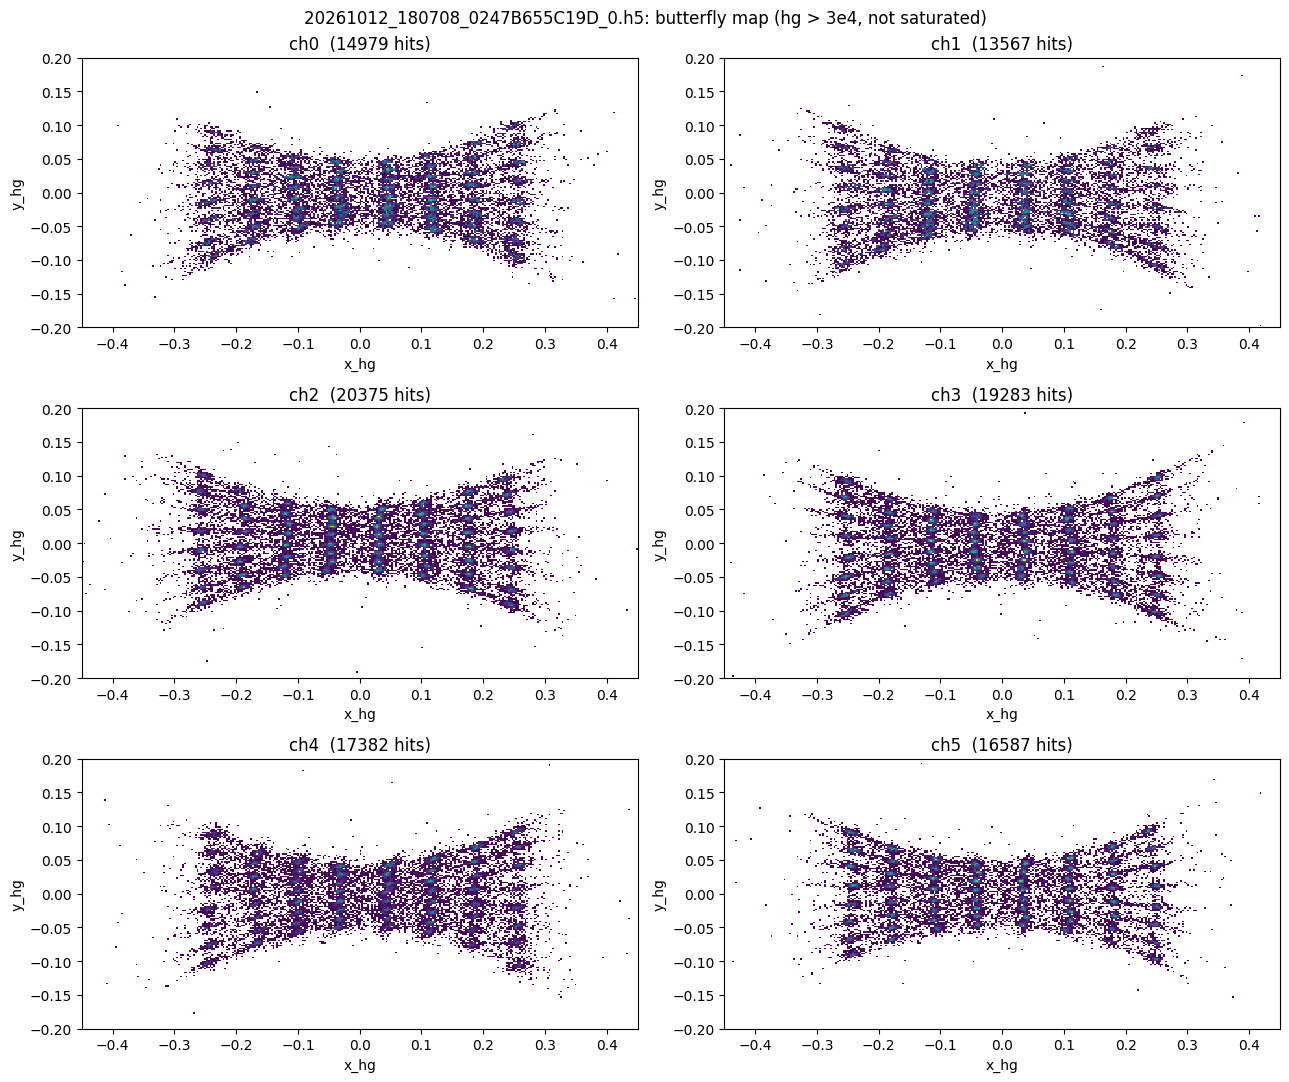

In [6]:
h5s = sorted(p for p in PSA_DATA.glob("*.h5") if not p.name.endswith("_adc.h5"))
try:
    import h5py
except ImportError:
    h5py = None
if h5s and h5py:
    with h5py.File(h5s[0]) as f:
        ch, x, y, hg = f["ch"][:], f["x_hg"][:], f["y_hg"][:], f["hg"][:]
        sat = (f["satu_h"][:] != 0) | (f["satu_l"][:] != 0)
    fig, axs = plt.subplots(3, 2, figsize=(13, 11))
    for c, a in enumerate(axs.flat):
        s = (ch == c) & ~sat & (hg > 3e4)
        a.hist2d(x[s], y[s], bins=[300, 200], range=[[-0.45, 0.45], [-0.2, 0.2]], cmap="viridis", cmin=1)
        a.set_title(f"ch{c}  ({s.sum()} hits)"); a.set_xlabel("x_hg"); a.set_ylabel("y_hg")
    fig.suptitle(f"{h5s[0].name}: butterfly map (hg > 3e4, not saturated)")
    plt.tight_layout(); plt.show()
else:
    print("psa_decode.py の .h5 がありません(または h5py が無い):", PSA_DATA)

## 次へ

- 実行のしかた: リポジトリ直下の [README](../../README.md) と [`run_script/README.md`](../../run_script/README.md)
- 設定ファイルの書き方: [`config/README.md`](../../config/README.md)